In [1]:
from google.colab import output
from IPython.display import display, Javascript
from google.colab.output import eval_js
from base64 import b64decode

import cv2
import numpy as np
import matplotlib.pyplot as plt

In [2]:
def take_photo(filename='photo.jpg', quality=0.8):

    js = Javascript('''
    async function takePhoto(quality) {

        const div = document.createElement('div');

        const video = document.createElement('video');
        video.style.display = 'block';

        const stream = await navigator.mediaDevices.getUserMedia({
            video: true
        });

        document.body.appendChild(div);
        div.appendChild(video);

        video.srcObject = stream;

        await video.play();

        await new Promise(resolve => setTimeout(resolve, 1000));

        const canvas = document.createElement('canvas');

        canvas.width = video.videoWidth;
        canvas.height = video.videoHeight;

        canvas.getContext('2d').drawImage(video, 0, 0);

        stream.getVideoTracks()[0].stop();
        div.remove();

        return canvas.toDataURL('image/jpeg', quality);
    }
    ''')

    display(js)

    data = eval_js('takePhoto({})'.format(quality))

    binary = b64decode(data.split(',')[1])

    with open(filename, 'wb') as f:
        f.write(binary)

    return filename

In [20]:
filename = take_photo()

print("Image captured successfully!")

<IPython.core.display.Javascript object>

Image captured successfully!


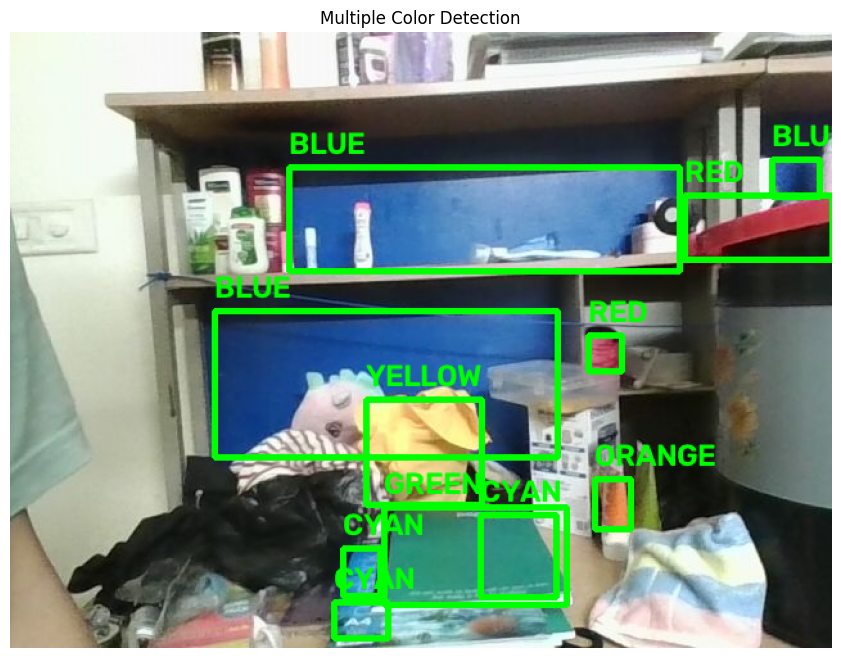

In [21]:
# Read image
image = cv2.imread("photo.jpg")

# Convert BGR to HSV
hsv = cv2.cvtColor(image, cv2.COLOR_BGR2HSV)


# ==========================================================
# DEFINE COLORS
# ==========================================================

colors = {

    "RED": [
        (np.array([0, 100, 100]), np.array([10, 255, 255])),
        (np.array([170, 100, 100]), np.array([180, 255, 255]))
    ],

    "ORANGE": [
        (np.array([10, 100, 100]), np.array([20, 255, 255]))
    ],

    "YELLOW": [
        (np.array([20, 100, 100]), np.array([35, 255, 255]))
    ],

    "GREEN": [
        (np.array([35, 80, 80]), np.array([85, 255, 255]))
    ],

    "CYAN": [
        (np.array([85, 80, 80]), np.array([100, 255, 255]))
    ],

    "BLUE": [
        (np.array([100, 100, 100]), np.array([140, 255, 255]))
    ],

    "PURPLE": [
        (np.array([140, 80, 80]), np.array([170, 255, 255]))
    ]
}


# ==========================================================
# DETECT EACH COLOR
# ==========================================================

kernel = np.ones((5, 5), np.uint8)

for color_name, ranges in colors.items():

    # Create empty mask
    mask = np.zeros(hsv.shape[:2], dtype=np.uint8)

    # Add all ranges for this color
    for lower, upper in ranges:

        current_mask = cv2.inRange(
            hsv,
            lower,
            upper
        )

        mask = cv2.bitwise_or(mask, current_mask)


    # Remove noise
    mask = cv2.morphologyEx(
        mask,
        cv2.MORPH_OPEN,
        kernel
    )

    mask = cv2.morphologyEx(
        mask,
        cv2.MORPH_CLOSE,
        kernel
    )


    # Find contours
    contours, _ = cv2.findContours(
        mask,
        cv2.RETR_EXTERNAL,
        cv2.CHAIN_APPROX_SIMPLE
    )


    # Detect objects
    for contour in contours:

        area = cv2.contourArea(contour)

        # Ignore tiny objects
        if area > 500:

            x, y, w, h = cv2.boundingRect(contour)

            # Draw bounding box
            cv2.rectangle(
                image,
                (x, y),
                (x + w, y + h),
                (0, 255, 0),
                3
            )

            # Write color name
            cv2.putText(
                image,
                color_name,
                (x, y - 10),
                cv2.FONT_HERSHEY_SIMPLEX,
                0.8,
                (0, 255, 0),
                2
            )


# ==========================================================
# DISPLAY RESULT
# ==========================================================

plt.figure(figsize=(12, 8))

plt.imshow(
    cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
)

plt.axis("off")
plt.title("Multiple Color Detection")

plt.show()

In [33]:
filename = take_photo()

print("Image captured successfully!")

<IPython.core.display.Javascript object>

Image captured successfully!


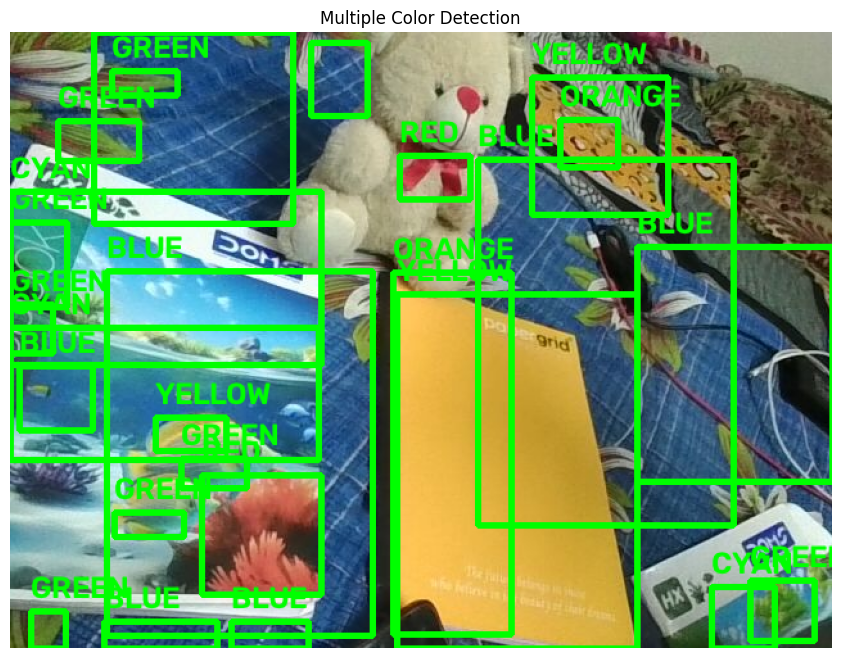

In [34]:
# Read image
image = cv2.imread("photo.jpg")

# Convert BGR to HSV
hsv = cv2.cvtColor(image, cv2.COLOR_BGR2HSV)


# ==========================================================
# DEFINE COLORS
# ==========================================================

colors = {

    "RED": [
        (np.array([0, 100, 100]), np.array([10, 255, 255])),
        (np.array([170, 100, 100]), np.array([180, 255, 255]))
    ],

    "ORANGE": [
        (np.array([10, 100, 100]), np.array([20, 255, 255]))
    ],

    "YELLOW": [
        (np.array([20, 100, 100]), np.array([35, 255, 255]))
    ],

    "GREEN": [
        (np.array([35, 80, 80]), np.array([85, 255, 255]))
    ],

    "CYAN": [
        (np.array([85, 80, 80]), np.array([100, 255, 255]))
    ],

    "BLUE": [
        (np.array([100, 100, 100]), np.array([140, 255, 255]))
    ],

    "PURPLE": [
        (np.array([140, 80, 80]), np.array([170, 255, 255]))
    ]
}


# ==========================================================
# DETECT EACH COLOR
# ==========================================================

kernel = np.ones((5, 5), np.uint8)

for color_name, ranges in colors.items():

    # Create empty mask
    mask = np.zeros(hsv.shape[:2], dtype=np.uint8)

    # Add all ranges for this color
    for lower, upper in ranges:

        current_mask = cv2.inRange(
            hsv,
            lower,
            upper
        )

        mask = cv2.bitwise_or(mask, current_mask)


    # Remove noise
    mask = cv2.morphologyEx(
        mask,
        cv2.MORPH_OPEN,
        kernel
    )

    mask = cv2.morphologyEx(
        mask,
        cv2.MORPH_CLOSE,
        kernel
    )


    # Find contours
    contours, _ = cv2.findContours(
        mask,
        cv2.RETR_EXTERNAL,
        cv2.CHAIN_APPROX_SIMPLE
    )


    # Detect objects
    for contour in contours:

        area = cv2.contourArea(contour)

        # Ignore tiny objects
        if area > 500:

            x, y, w, h = cv2.boundingRect(contour)

            # Draw bounding box
            cv2.rectangle(
                image,
                (x, y),
                (x + w, y + h),
                (0, 255, 0),
                3
            )

            # Write color name
            cv2.putText(
                image,
                color_name,
                (x, y - 10),
                cv2.FONT_HERSHEY_SIMPLEX,
                0.8,
                (0, 255, 0),
                2
            )


# ==========================================================
# DISPLAY RESULT
# ==========================================================

plt.figure(figsize=(12, 8))

plt.imshow(
    cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
)

plt.axis("off")
plt.title("Multiple Color Detection")

plt.show()